# Spam Email Classification


## Part 1 — Get to know our data

### 1. Import libraries

In [ ]:
import re
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

### 2. Load dataset

In [ ]:
df = pd.read_csv("emails.csv")
df.head(3)

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1


### 3. Check our labels

In [ ]:
print("Shape:", df.shape)
print(df["spam"].value_counts())
print("Missing values:", df.isna().sum())

Shape: (5728, 2)
spam
0    4360
1    1368
Name: count, dtype: int64
Missing values: text    0
spam    0
dtype: int64


  0 = Ham, 1 = Spam

### 4. Plot the label distribution

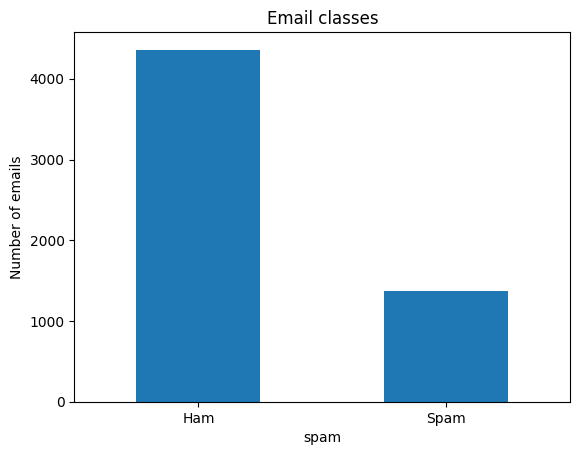

In [ ]:
df["spam"].map({0: "Ham", 1: "Spam"}).value_counts().plot.bar(rot=0, title="Email classes")
plt.ylabel("Number of emails")
plt.show()

## Part 2 — Prepare text

### 5. Remove missing or repeated rows

In [ ]:
df = df.dropna(subset=["text", "spam"]).drop_duplicates().copy()
print("Clean rows:", len(df))

Clean rows: 5695


### 6. Text cleaning

In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

### 7. See before and after

In [ ]:
df["clean_text"] = df["text"].astype(str).apply(clean_text)
print("BEFORE:", df["text"].iloc[0][:180])
print("AFTER: ", df["clean_text"].iloc[0][:180])

BEFORE: Subject: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a go
AFTER:  subject naturally irresistible your corporate identity lt is really hard to recollect a company the market is full of suqgestions and the information isoverwhelminq but a good catc


### 8. Split train and test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["spam"], test_size=0.2,
    random_state=42, stratify=df["spam"]
)
print("Train:", len(X_train), "Test:", len(X_test))

Train: 4556 Test: 1139


## Part 3 — Text to numbers

### 9. CountVectorizer: number of occurrences

In [ ]:
count_demo = CountVectorizer()
count_demo.fit(["free gift today", "free class today"])
print(count_demo.get_feature_names_out())
print(count_demo.transform(["free gift today"]).toarray())

['class' 'free' 'gift' 'today']
[[0 1 1 1]]


### 10. TF-IDF: importance of words
Both produce numeric features. **TF-IDF** gives less weight to words that appear in many documents.

In [ ]:
tfidf_demo = TfidfVectorizer()
tfidf_demo.fit(["free gift today", "free class today"])
print(tfidf_demo.get_feature_names_out())
print(tfidf_demo.transform(["free gift today"]).toarray().round(2))

['class' 'free' 'gift' 'today']
[[0.  0.5 0.7 0.5]]


## Part 4 — Train and compare

### 11. Model A: CountVectorizer + Naive Bayes

In [ ]:
model_a = Pipeline([
    ("vectorizer", CountVectorizer(stop_words="english")),
    ("classifier", MultinomialNB())
])
model_a.fit(X_train, y_train)

Pipeline(steps=[('vectorizer', CountVectorizer(stop_words='english')),
                ('classifier', MultinomialNB())])

### 12. Model B: TF-IDF + Logistic Regression

In [ ]:
model_b = Pipeline([
    ("vectorizer", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model_b.fit(X_train, y_train)

Pipeline(steps=[('vectorizer', TfidfVectorizer(stop_words='english')),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

### 13. Predict on the same test emails

In [ ]:
pred_a = model_a.predict(X_test)
pred_b = model_b.predict(X_test)
print("First 10 predictions (A):", pred_a[:10])
print("First 10 predictions (B):", pred_b[:10])

First 10 predictions (A): [0 0 0 0 0 0 0 0 1 1]
First 10 predictions (B): [0 0 0 0 0 0 0 0 1 1]


### 14. Compare Spam F1 scores

In [ ]:
scores = pd.DataFrame({
    "Model": ["Count + Naive Bayes", "TF-IDF + Logistic Regression"],
    "Spam F1": [f1_score(y_test, pred_a), f1_score(y_test, pred_b)]
})
scores

,Model,Spam F1
0,Count + Naive Bayes,0.983666
1,TF-IDF + Logistic Regression,0.978571


### 15. Detailed precision / recall / F1 for both models

In [ ]:
print("MODEL A", classification_report(y_test, pred_a, target_names=["Ham", "Spam"]))
print("MODEL B", classification_report(y_test, pred_b, target_names=["Ham", "Spam"]))

MODEL A               precision    recall  f1-score   support

         Ham       1.00      0.99      0.99       865
        Spam       0.98      0.99      0.98       274

    accuracy                           0.99      1139
   macro avg       0.99      0.99      0.99      1139
weighted avg       0.99      0.99      0.99      1139

MODEL B               precision    recall  f1-score   support

         Ham       1.00      0.99      0.99       865
        Spam       0.96      1.00      0.98       274

    accuracy                           0.99      1139
   macro avg       0.98      0.99      0.99      1139
weighted avg       0.99      0.99      0.99      1139



## Part 5 — Understand mistakes

### 16. Choose the model with the higher Spam F1

In [ ]:
best_model = model_a if scores.loc[0, "Spam F1"] >= scores.loc[1, "Spam F1"] else model_b
best_name = scores.loc[scores["Spam F1"].idxmax(), "Model"]
best_pred = best_model.predict(X_test)
print("Best model:", best_name)

Best model: Count + Naive Bayes


### 17. Confusion Matrix

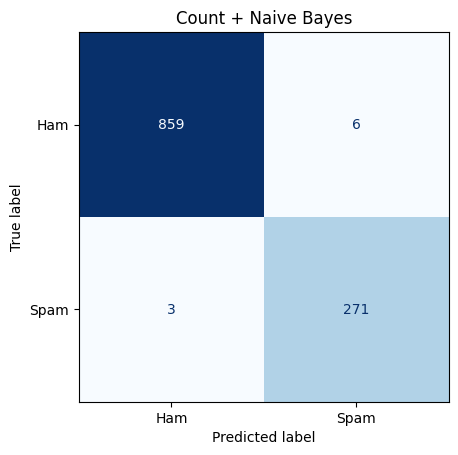

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["Ham", "Spam"], cmap="Blues", colorbar=False
)
plt.title(best_name)
plt.show()


Rows = actual labels, columns = predicted labels. Focus on **Spam predicted as Ham** (missed Spam).

### 18. Inspect a few wrong predictions (optional)

In [ ]:
errors = pd.DataFrame({"email": X_test, "actual": y_test, "predicted": best_pred})
errors[errors["actual"] != errors["predicted"]].head(3)

,email,actual,predicted
3733,subject department of energy is deploying a co...,0,1
122,subject help television in by seat to my knowe...,1,0
2842,subject a basic idea of price offer matching c...,0,1


## Part 6 — Save and reuse

### 19. Save the FULL pipeline (vectorizer + model)

In [ ]:
joblib.dump(best_model, "spam_pipeline.joblib")
print("Saved: spam_pipeline.joblib")

Saved: spam_pipeline.joblib


### 20. Load the pipeline

In [ ]:
loaded_model = joblib.load("spam_pipeline.joblib")

### 21. Try your own emails

In [ ]:
new_emails = [
    "Congratulations! Claim your FREE cash prize now!",
    "Hi, our meeting is tomorrow at 10 AM."
]
clean_emails = [clean_text(email) for email in new_emails]
labels = loaded_model.predict(clean_emails)
for email, label in zip(new_emails, labels):
    print("Spam" if label == 1 else "Ham", "—", email)

Spam — Congratulations! Claim your FREE cash prize now!
Ham — Hi, our meeting is tomorrow at 10 AM.
